we fitted u+1-13C (combined) and looked at 20% best fitting samples. 
THen looked at statisctically different reactions : has the fitting impacted the sampled distributions .
NOw we look WT vs TM6, with reducing dimensions of the space and looking if there might be a multimode distribution

In [9]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux

import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt
from analysis import config_13c as config
import umap

In [10]:
import thermo_flux

In [11]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [12]:
condition = cond = 'TM6'

In [13]:
model=config.model
net_flux_df=config.full_flux_df(condition)
# net_flux_df=pd.read_csv(config.flux_file(condition),index_col=0)
# net_flux_df.columns=[int(c) for c in range(len(net_flux_df.columns))]
obj_vals=config.obj_vals(condition)
# obj_vals=obj_vals[obj_vals<np.percentile(obj_vals,85)]
# accepted_samples=obj_vals[obj_vals<=config.find_plateau(obj_vals)].index
nperc=10
accepted_samples=obj_vals[obj_vals<=np.percentile(obj_vals,nperc)].index
# accepted_samples=accepted_samples[:28] ### previously the cutoff justifcation was based on umap reduciton : we take the N first samples that are together in one cluster.
## was doing it manually I thnk ? ## todo when we have 1000 samples for both condition
# len(accepted_samples)


In [14]:
net_flux_df_umap=net_flux_df.loc[:,obj_vals.index]


superpose stoichiometric sampling in the umap projected space

In [18]:
## plot umap reduction in 2d, with colorbar (fig 5c). color points by their 13C score colormap
def _calc_embedding(net_flux_df,accepted_samples=None,nneigh=6,min_dist=0.1,**kwargs):
    X=net_flux_df
    if accepted_samples is not None:
        X=net_flux_df.loc[:,accepted_samples]
    reducer = umap.UMAP(n_neighbors=nneigh, min_dist=min_dist,**kwargs)
    embedding = reducer.fit_transform(X.T).T
    return embedding

In [40]:
net_flux_df_umap

,754,651,892,770,818,757,80,271,790,981,...,457,236,0,642,978,616,134,874,998,912
ASNS1,0.024697,0.025042,0.025934,0.026292,0.025312,0.025615,0.024935,0.025238,0.025007,0.025322,...,0.024653,0.025581,0.024903,0.025244,0.025383,0.025300,0.024814,0.025189,0.025018,0.024889
ASPK,0.106309,0.111980,0.120235,0.119709,0.114861,0.110731,0.107112,0.113016,0.110693,0.108328,...,0.112941,0.110258,0.111911,0.109776,0.114892,0.117542,0.112025,0.112933,0.118095,0.111948
ASPTA,-0.332031,-0.364210,-0.362269,-0.372765,-0.347804,-0.436706,-0.341340,-0.439573,-0.384997,-0.379528,...,-0.151622,-0.019778,-0.259349,-0.204526,-0.070684,-0.052816,-0.338876,-1.544531,-0.071347,-0.001367
ASPTAm,0.010951,0.034458,0.016509,0.024418,0.012822,0.103224,0.017392,0.107080,0.056840,0.050995,...,-0.175706,-0.312935,-0.069125,-0.124773,-0.264946,-0.284737,0.011067,1.212550,-0.264312,-0.327017
ASAD,0.106309,0.111980,0.120235,0.119709,0.114861,0.110731,0.107112,0.113016,0.110693,0.108328,...,0.112941,0.110258,0.111911,0.109776,0.114892,0.117542,0.112025,0.112933,0.118095,0.111948
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SUCCPItm-2-2,-0.022800,-0.020647,-0.041445,-0.020057,-0.124261,-0.204930,-0.227249,-0.083451,-0.006749,-0.115326,...,-0.043360,-0.002818,-0.294951,-0.023216,-0.357305,-0.394019,-0.359969,-0.046867,-0.260468,-0.465000
SUCFUMtm-2-2,-0.133405,-0.272979,0.005895,0.029987,-0.158578,-0.189890,-0.108601,-0.047145,-0.449744,-0.259605,...,-0.246556,-0.247426,0.014583,-0.214203,0.078281,0.158410,0.022893,-0.137091,0.016210,-0.374862
THRtm+0,0.045193,0.045825,0.047456,0.048111,0.046319,0.046873,0.045628,0.046183,0.045760,0.046337,...,0.045112,0.046810,0.045570,0.046193,0.046449,0.046296,0.045406,0.046093,0.045781,0.045544
biomass_ce,0.242844,0.246237,0.255003,0.258524,0.248893,0.251867,0.245179,0.248164,0.245889,0.248988,...,0.242410,0.251532,0.244870,0.248218,0.249590,0.248768,0.243989,0.247680,0.246002,0.244727


In [34]:
### in notebook 0a_tm6 we had genereated flux samples from stoichiometric model only 
flux_samples=pd.read_csv(f'{config.RESULTS_FOLDER}/a_fluxspace/TM6_stoichio_fluxsamples.csv',index_col=0).loc[net_flux_df.index]
flux_samples

,0,1,2,3,4,5,6,7,8,9,...,9998,9999,10000,10001,10002,10003,10004,10005,10006,10007
ASNS1,0.834821,0.532353,0.552485,1.010987,0.902212,0.625347,1.107047,0.556717,1.604835,2.439272,...,0.803584,0.861288,0.985393,1.037505,0.974259,0.845775,0.816913,0.718436,0.598713,0.705995
ASPK,-57.286343,-36.110626,9.955996,16.977393,-48.178948,-21.471619,7.569133,20.861118,140.164711,96.514768,...,42.327408,24.996750,43.005212,66.948272,22.409987,-15.917114,7.739821,0.721063,1.035144,5.534795
ASPTA,-307.264769,-228.162916,-133.338753,-110.282102,-251.778445,-112.331357,-62.234451,-49.349320,-201.494021,-148.437398,...,-34.199401,-25.625011,9.399942,14.568967,24.833869,42.211096,43.385349,58.359603,69.961426,52.518253
ASPTAm,357.291373,259.644115,118.578259,84.512996,292.111611,128.364854,45.038255,23.646902,47.373399,30.710317,...,-15.116105,-6.861643,-60.974294,-90.539553,-55.716177,-33.648976,-58.229180,-65.328307,-76.203073,-64.192498
ASAD,-57.286343,-36.110626,9.955996,16.977393,-48.178948,-21.471619,7.569133,20.861118,140.164711,96.514768,...,42.327408,24.996750,43.005212,66.948272,22.409987,-15.917114,7.739821,0.721063,1.035144,5.534795
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SUCCPItm-2-2,182.989170,38.768044,-194.538639,-135.048170,-87.916317,-150.590084,-120.435300,-227.382397,-129.584862,-116.216759,...,227.043332,202.317258,181.544909,265.210169,242.211198,192.934678,198.569241,190.653977,185.404443,190.022784
SUCFUMtm-2-2,-174.509297,-93.449158,-27.330785,-28.176809,6.262759,26.585275,16.959616,90.402368,40.620215,43.241275,...,-152.519058,-152.903590,-160.065885,-192.356932,-210.817481,-155.651380,-135.768918,-149.157348,-162.341447,-153.754918
THRtm+0,1.527632,0.974148,1.010987,1.849997,1.650950,1.144318,2.025776,1.018731,2.936675,4.463604,...,1.470472,1.576064,1.803162,1.898522,1.782789,1.547676,1.494862,1.314661,1.095579,1.291895
biomass_ce,8.208660,5.234539,5.432493,9.940878,8.871305,6.148939,10.885417,5.474106,15.780089,23.984977,...,7.901513,8.468909,9.689213,10.201622,9.579738,8.316367,8.032576,7.064272,5.887045,6.941938


/home/nathan/anaconda3/envs/thermoflux_0.1/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


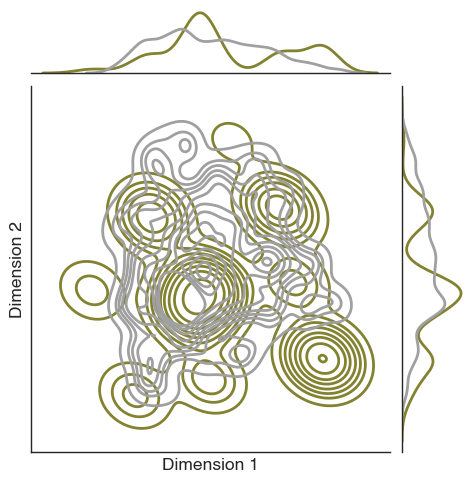

In [ ]:
## plot umap reduction in 2d, with colorbar (fig 5c). color points by their 13C score colormap
## with top and bootom kde plot
# scat_kws={'alpha': 1, 'edgecolor': palette[1]}#,'color':palette[1]}
color=palette[0] if condition=='WT' else palette[2]
palette_cmap=sns.light_palette(color,as_cmap=True)

# accepted_samples=accepted_samples[:3]

embedding=_calc_embedding(net_flux_df_umap,nneigh=10)
g=sns.jointplot(x=embedding[0], y=embedding[1],height=5,kind='kde',color=color,
                    linewidths=2,                      # joint contour lines
    marginal_kws=dict(linewidth=2),
                )#,c=obj_vals,cmap=palette_cmap.reversed(),)#
            #   scatter_kws=scat_kws)
io_func.scale_rcparams(g.fig,scalingf=0.5)
    
embedding_SM=_calc_embedding(flux_samples[:1000],nneigh=10)

sns.kdeplot( #or scatter
    x=embedding_SM[0],
    y=embedding_SM[1],
    ax=g.ax_joint,#kind='hex',
    color='#a0a0a0',
    # fill=False,        # set True if you want filled contours
    # levels=10,         # number of contour levels
    linewidths=2
)# g.ax_joint.cla()  # Clear main (joint) plot


# --- KDE on marginal X axis ---
sns.kdeplot(
    x=embedding_SM[0],
    ax=g.ax_marg_x,
    color='#a0a0a0',
    fill=False,
    linewidth=2
)

# --- KDE on marginal Y axis ---
sns.kdeplot(
    y=embedding_SM[1],
    ax=g.ax_marg_y,
    color='#a0a0a0',
    fill=False,
    linewidth=2
)

g.ax_joint.set_yticks([])
g.ax_joint.set_xticks([])
g.ax_joint.set_xlabel('Dimension 1')
g.ax_joint.set_ylabel('Dimension 2')


# ax.

# plt.savefig(f'SuppFigures/Sfig_13C_{condition}_UMAP_withSM.png',dpi=300,bbox_inches='tight') ##with light palette and palette[2]
# plt.savefig(f'SuppFigures/Sfig_13C_{condition}_UMAP_withSM.svg',dpi=300,bbox_inches='tight')
